# Case 2: Panama Canal drought and Red Sea diversions, 2023–24

**What this notebook does.** It dates the two shocks from chokepoint transits, then shows how sea freight of data center electrical gear from Asia responded (longer routes, a different coast of arrival, air) and what that did to the transport emissions of delivering a tonne to the US. Servers barely move by sea to the East Coast, so the gear carries the case.

**How it's organised.** Each section computes with the engine (`engine/`, pure functions) on data read by `analysis/src/shockt_analysis/core.py`, the only code that touches the database. The baseline and the shock-dating rules come from `inputs/cases/panama_red_sea_2023/shock_windows.yaml`; the windows are what those rules find. The last section writes the derived evidence and proposes causal labels.

**Accounting, not attribution.** The numbers say what changed (DERIVED). Why it changed is the team's reading (INFERENCE), stated separately with its competing explanations. See the [Case 2 analysis plan](../../docs/plans/case-2-analysis.md).

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it never writes to the database.

## 1. Setup

The parameters below are the notebook's analytical choices: the products (the Case 2 codes in `config/hs_codes.yaml`), the origins shown on their own (the steady gear lanes, plus two lanes that sail via Suez), the states used for the inland-routing check (the proposal's), and the distance a closed passage must add before a route counts as using it.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
import yaml
from shockt_engine import (
    diversion_rate,
    load_leg_factors,
    mix_decomposition,
    select_factors,
    window_summary,
)

from shockt_analysis import case2, cases, core
from shockt_analysis.settings import REPO_ROOT, get_settings

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_float_precision(3)

CASE = "panama_red_sea_2023"
CASE_DIR = REPO_ROOT / "inputs" / "cases" / CASE
NOTEBOOK = "analysis/case2/case2_panama_red_sea.ipynb"

GEAR = ["850421", "850422", "850423", "850433", "850434", "853720"]
NAMED_ORIGINS = ["KOR", "CHN", "TWN"]
SUEZ_EXAMPLES = ["VNM", "IND"]
EAST_BOUND = ["VA", "GA", "OH"]
WEST_CONTROL = ["CA", "OR", "WA", "AZ"]
SEPARATE = ["TX", "IL"]
PASSAGE_TOLERANCE_KM = 1.0

case_windows = case2.load_case_windows(CASE_DIR / "shock_windows.yaml")
case_windows

CaseWindows(baseline=Window(name='baseline', first=datetime.date(2022, 1, 1), last=datetime.date(2023, 6, 1)), rules=(ShockRule(shock='panama_drought', chokepoint_id='chokepoint2', series='n_total', side='below', max_gap=1, starts_by=datetime.date(2024, 12, 1)), ShockRule(shock='red_sea_diversions', chokepoint_id='chokepoint4', series='n_container', side='below', max_gap=1, starts_by=datetime.date(2024, 12, 1))))

Read everything the notebook needs in one connection, and choose each mode's emission factor (`engine/config/leg_factors.yaml`).

In [2]:
with core.connect(get_settings()) as conn:
    transits = core.chokepoint_transits(conn)
    voyage_lanes = core.voyage_lanes(conn)
    port_tonnes = core.imports_by_port(conn, GEAR)
    state_tonnes = core.imports_by_state(conn, GEAR)
    state_port = core.state_port_vessel(conn, "asia")
    supply = core.supply(conn, GEAR)
    origins = core.origins(conn)
    node_weights = core.node_weights(conn, GEAR)
    observed_sea = core.observed_sea(conn)
    distances = {seed: core.distances(conn, seed) for seed in ("sea", "air", "road", "rail")}
    sea_scenarios = {
        scenario: core.distances(conn, "sea", scenario)
        for scenario in ("open", "panama_closed", "red_sea_closed", "panama_and_red_sea_closed")
    }
    crossing_plants = core.crossing_plants(conn)
    factor_rows = core.factors(conn)
    loads = core.current_loads(
        conn,
        [
            "census_hs",
            "census_porths",
            "census_statehs",
            "census_state_port",
            "portwatch_chokepoints",
            "climatetrace_voyages",
            "bts_t100_segments",
            "uk_ghg_conversion_factors",
            "epa_ghg_transport_factors",
            "epa_ghg_gwp",
            "ourairports_airports",
            "geonames_cities",
        ],
    )

leg_factors = select_factors(factor_rows, load_leg_factors())
context = cases.LaneContext(
    weights=node_weights,
    observed_sea=observed_sea,
    distances=distances,
    factors={mode: f.wtw_kg_co2e_per_tkm for mode, f in leg_factors.items()},
    crossing_plants=crossing_plants,
)
asian = set(origins.filter(pl.col("region") == "asia")["census_cty_code"].to_list())
asia_ports = port_tonnes.filter(pl.col("region") == "asia")
cty_code = dict(zip(origins["iso3"].to_list(), origins["census_cty_code"].to_list(), strict=True))
loads

dataset,partitions,latest_load,code_versions
str,i64,str,str
"""bts_t100_segments""",5,"""2026-10-13 01:07:44.08102+00""","""d3cc89b-dirty"""
"""census_hs""",392,"""2026-10-13 19:50:48.911328+00""","""e097cd6"""
"""census_porths""",392,"""2026-10-13 19:58:35.528908+00""","""e097cd6"""
"""census_state_port""",18,"""2026-10-12 23:50:57.426304+00""","""1f136b3"""
"""census_statehs""",392,"""2026-10-13 20:06:18.115574+00""","""e097cd6"""
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""
"""epa_ghg_gwp""",1,"""2026-10-12 22:52:51.50207+00""","""20b5845"""
"""epa_ghg_transport_factors""",1,"""2026-10-12 22:52:48.687086+00""","""20b5845"""
"""geonames_cities""",1,"""2026-10-12 17:16:49.214925+00""","""ae62e94-dirty"""


## 2. Shock dating

Each shock's rule (in `shock_windows.yaml`) finds the months after the baseline whose transits per reported day fall below the baseline's lowest month, allowing one month back inside the range before a run ends. Panama counts all ship types, because the Canal Authority gave full container vessels priority for slots (`ev_panama_acp_a35_2023_capacity_cut`); Bab el-Mandeb counts container ships. Runs that start after the rule's `starts_by` month belong to later events and are listed, not used.

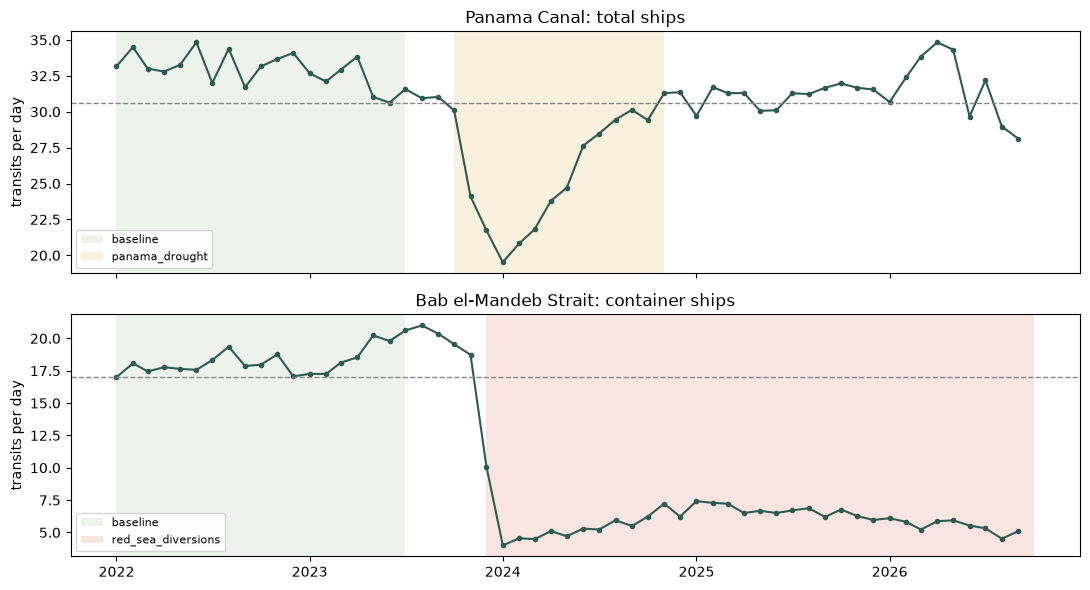

shock,chokepoint,series,baseline range per day,window,later runs (not used),last full month
str,str,str,str,str,str,str
"""panama_drought""","""chokepoint2""","""n_total""","""30.63–34.83""","""2023-10 to 2024-10""","""2025-01 to 2025-01, 2025-05 to…","""2026-09"""
"""red_sea_diversions""","""chokepoint4""","""n_container""","""17.0–20.23""","""2023-12 to 2026-09""","""""","""2026-09"""


In [3]:
shock_windows, dating = case2.shock_windows(transits, case_windows)
windows = [case_windows.baseline, *shock_windows]
by_name = {w.name: w for w in windows}
WINDOW_COLORS = {
    "baseline": "#d9e5d6",
    "panama_drought": "#f3dfb6",
    "red_sea_diversions": "#f0c7c0",
}


def shade_windows(ax, names=None):
    for w in windows:
        if names is not None and w.name not in names:
            continue
        ax.axvspan(
            w.first,
            date(w.last.year + (w.last.month == 12), w.last.month % 12 + 1, 1),
            color=WINDOW_COLORS.get(w.name, "#dddddd"),
            alpha=0.45,
            lw=0,
            label=w.name,
        )


fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, rule in zip(axes, case_windows.rules, strict=True):
    series = case2.daily_series(transits, rule.chokepoint_id, rule.series)
    name = transits.filter(pl.col("chokepoint_id") == rule.chokepoint_id)["chokepoint_name"][0]
    shade_windows(ax, ["baseline", rule.shock])
    ax.plot(list(series), list(series.values()), color="#2d5b4f", marker=".")
    found = dating[rule.shock]
    ax.axhline(found["baseline_low_per_day"], color="#888888", ls="--", lw=1)
    ax.set_ylabel("transits per day")
    ax.set_title(f"{name}: {rule.series.removeprefix('n_')} ships")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()
pl.DataFrame(
    [
        {
            "shock": shock,
            "chokepoint": d["chokepoint_id"],
            "series": d["series"],
            "baseline range per day": f"{d['baseline_low_per_day']}–{d['baseline_high_per_day']}",
            "window": " to ".join(d["runs"][0]) if d["runs"] else None,
            "later runs (not used)": ", ".join(" to ".join(r) for r in d["later_runs"]),
            "last full month": d["last_month"],
        }
        for shock, d in dating.items()
    ]
)

The two windows overlap from December 2023 to October 2024. They stay separate shocks, as Shock-T requires; the overlap is in the causal labels. The windows match the policy record: the Canal Authority cut capacity in stages from July 2023 to February 2024 and restored it from June to September 2024, and the carriers paused Red Sea transits in December 2023 (`evidence.yaml`).

## 3. Route length

**Observed voyages.** The mean distance of container voyages from Asia to each US coast region, by month (Climate TRACE, `agg_voyage_lanes_monthly`), and per window.

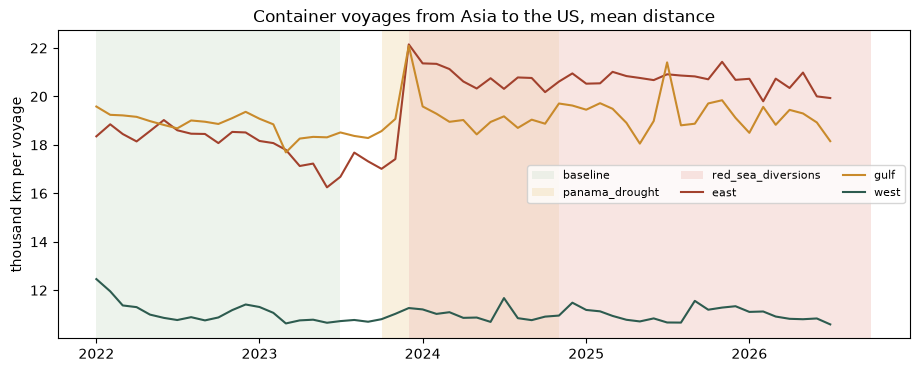

coast,baseline,panama_drought,red_sea_diversions,panama_drought vs baseline,red_sea_diversions vs baseline
str,f64,f64,f64,f64,f64
"""east""",18279.324,20408.546,20782.868,0.116,0.137
"""gulf""",18914.909,19233.343,19334.211,0.017,0.022
"""west""",11105.232,11002.413,11003.594,-0.009,-0.009


In [4]:
asia_voyages = (
    voyage_lanes.filter(pl.col("origin_region") == "asia")
    .group_by("month", "end_coast_region")
    .agg(pl.col("total_distance_km").sum(), pl.col("n_voyages").sum())
    .with_columns((pl.col("total_distance_km") / pl.col("n_voyages")).alias("mean_km"))
    .sort("month")
)
fig, ax = plt.subplots(figsize=(11, 4))
shade_windows(ax)
for coast, color in [("east", "#a2412d"), ("gulf", "#c98a2b"), ("west", "#2d5b4f")]:
    part = asia_voyages.filter(pl.col("end_coast_region") == coast)
    ax.plot(part["month"].to_list(), (part["mean_km"] / 1000).to_list(), label=coast, color=color)
ax.set_ylabel("thousand km per voyage")
ax.set_title("Container voyages from Asia to the US, mean distance")
ax.legend(fontsize=8, ncols=3)
plt.show()

route_rows = []
for coast in ("east", "gulf", "west"):
    part = asia_voyages.filter(pl.col("end_coast_region") == coast)
    values = dict(zip(part["month"].to_list(), part["mean_km"].to_list(), strict=True))
    weights = dict(zip(part["month"].to_list(), part["n_voyages"].to_list(), strict=True))
    for name, s in window_summary(values, windows, weights).items():
        route_rows.append({"coast": coast, "window": name, "mean_km": s.mean, "months": s.months})
route_length = pl.DataFrame(route_rows).pivot(on="window", index="coast", values="mean_km")
route_length.with_columns(
    *[
        (pl.col(w.name) / pl.col("baseline") - 1).alias(f"{w.name} vs baseline")
        for w in shock_windows
    ]
)

**Which lanes use which passage.** A departure port → US seaport pair uses a passage if its `searoute` distance with the passage closed is longer than with it open (`shockt_engine.passage_used`). For each origin's vessel lane to a coast, the share of its port pairs (weighted as in its sea leg, over the baseline) that use each passage, its modelled distance in each scenario, and the sea leg each window actually used (observed where the origin has voyages to those ports, else open-route).

In [5]:
flags = case2.passage_flags(
    sea_scenarios["open"],
    {"panama": sea_scenarios["panama_closed"], "red_sea": sea_scenarios["red_sea_closed"]},
    PASSAGE_TOLERANCE_KM,
)
passage_rows = []
for iso3 in NAMED_ORIGINS + SUEZ_EXAMPLES:
    cty = cty_code[iso3]
    for coast in ("east", "gulf"):
        uses = case2.lane_passage_shares(
            context, flags, cty, iso3, GEAR, coast, case_windows.baseline
        )
        if not uses:
            continue
        modelled = case2.modelled_sea_km(
            context, sea_scenarios, cty, iso3, GEAR, coast, case_windows.baseline
        )
        row = {
            "iso3": iso3,
            "coast": coast,
            "via panama": uses["panama"],
            "via red sea": uses["red_sea"],
            **{f"{k} km": v for k, v in modelled.items()},
        }
        for w in windows:
            result, _ = case2.lane_result(context, cty, iso3, GEAR, "vessel", w, coast)
            if result is not None:
                row[f"used km, {w.name}"] = result.legs[0].km
                row[f"observed share, {w.name}"] = result.legs[0].observed_share
        passage_rows.append(row)
passages = pl.DataFrame(passage_rows)
passages

iso3,coast,via panama,via red sea,open km,panama_closed km,red_sea_closed km,panama_and_red_sea_closed km,"used km, baseline","observed share, baseline","used km, panama_drought","observed share, panama_drought","used km, red_sea_diversions","observed share, red_sea_diversions"
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""KOR""","""east""",1.000,0.000,18664.567,24001.574,18664.567,27576.503,18910.393,0.699,19849.258,0.886,19554.903,0.938
"""KOR""","""gulf""",1.000,0.000,18069.740,26419.247,18069.740,28691.873,18470.524,0.805,18575.523,0.907,18673.280,0.931
"""CHN""","""east""",1.000,0.000,19915.050,22863.100,19915.050,26556.031,20371.790,0.873,21437.117,0.842,20940.200,0.831
"""CHN""","""gulf""",1.000,0.000,19695.927,24945.918,19695.927,27237.099,19964.215,1.000,20928.454,0.990,20557.499,0.996
"""TWN""","""east""",1.000,0.000,20212.029,22270.763,20212.029,25829.484,20212.029,0.000,20229.109,0.000,20233.768,0.000
"""TWN""","""gulf""",1.000,0.000,19498.820,24931.108,19498.820,27179.679,19498.820,0.000,19538.224,0.000,19512.825,0.000
"""VNM""","""east""",0.000,1.000,20085.383,20085.383,22602.733,24255.869,20624.309,1.000,23568.795,1.000,24640.568,0.929
"""IND""","""east""",0.000,1.000,15905.535,15905.535,21536.927,21536.927,15942.435,0.175,20913.595,0.969,21205.726,0.921
"""IND""","""gulf""",0.000,1.000,18063.621,18063.621,22723.036,22723.036,18063.621,0.000,18061.758,0.000,18058.682,0.000


In [6]:
def passage_tonnage(window):
    """The share of the gear's Asian vessel tonnage to the East and Gulf coasts whose lanes use
    each passage."""
    part = (
        asia_ports.filter(
            pl.col("hs6").is_in(GEAR)
            & (pl.col("mode") == "vessel")
            & pl.col("coast_region").is_in(["east", "gulf"])
            & pl.col("month").is_between(window.first, window.last)
        )
        .group_by("census_cty_code", "iso3", "coast_region")
        .agg(pl.col("weight_t").sum())
    )
    totals = {"panama": 0.0, "red_sea": 0.0, "neither": 0.0}
    for row in part.iter_rows(named=True):
        uses = case2.lane_passage_shares(
            context, flags, row["census_cty_code"], row["iso3"], GEAR, row["coast_region"], window
        )
        p, r = uses.get("panama", 0.0), uses.get("red_sea", 0.0)
        totals["panama"] += row["weight_t"] * p
        totals["red_sea"] += row["weight_t"] * r
        totals["neither"] += row["weight_t"] * max(0.0, 1 - p - r)
    total = sum(totals.values())
    return {"window": window.name, "tonnes": total, **{k: v / total for k, v in totals.items()}}


passage_shares = pl.DataFrame([passage_tonnage(w) for w in windows])
passage_shares

window,tonnes,panama,red_sea,neither
str,f64,f64,f64,f64
"""baseline""",65313.667,0.827,0.172,0.000
"""panama_drought""",118022.808,0.872,0.128,0.000
"""red_sea_diversions""",366517.408,0.895,0.105,0.000


## 4. Port of entry

Each coast region's share of the gear's Asian vessel tonnage, by window and by half-year. A rising West Coast share is the response the proposal names, but it can also come from more freight bound for western states, so the two checks below look at where the freight was going.

In [7]:
asia_vessel = asia_ports.filter(pl.col("mode") == "vessel").with_columns(
    pl.when(pl.col("coast_region").is_in(case2.COASTS))
    .then(pl.col("coast_region"))
    .otherwise(pl.lit("other"))
    .alias("coast")
)
coast_shares = cases.window_shares(asia_vessel, windows, ["coast"])
coast_table = coast_shares.pivot(on="window", index="coast", values="share").select(
    "coast", *[w.name for w in windows]
)
coast_table

coast,baseline,panama_drought,red_sea_diversions
str,f64,f64,f64
"""east""",0.276,0.274,0.225
"""gulf""",0.311,0.290,0.267
"""other""",0.012,0.005,0.006
"""west""",0.401,0.431,0.503


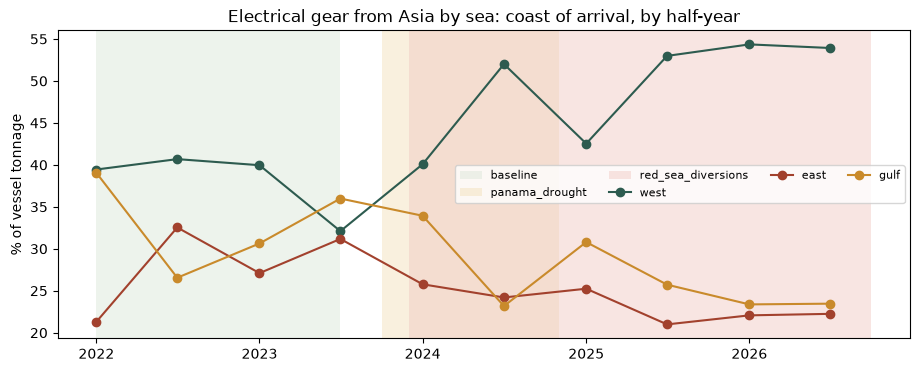

In [8]:
half_year = (
    asia_vessel.with_columns(
        pl.date(
            pl.col("month").dt.year(), ((pl.col("month").dt.month() - 1) // 6) * 6 + 1, 1
        ).alias("half")
    )
    .group_by("half", "coast")
    .agg(pl.col("weight_t").sum())
    .with_columns((pl.col("weight_t") / pl.col("weight_t").sum().over("half")).alias("share"))
    .sort("half")
)
fig, ax = plt.subplots(figsize=(11, 4))
shade_windows(ax)
for coast, color in [("west", "#2d5b4f"), ("east", "#a2412d"), ("gulf", "#c98a2b")]:
    part = half_year.filter(pl.col("coast") == coast)
    ax.plot(
        part["half"].to_list(),
        (part["share"] * 100).to_list(),
        marker="o",
        label=coast,
        color=color,
    )
ax.set_ylabel("% of vessel tonnage")
ax.set_title("Electrical gear from Asia by sea: coast of arrival, by half-year")
ax.legend(fontsize=8, ncols=4)
plt.show()

**Inland-routing check 1, all goods** (Census State/Port file, quarterly): the share of vessel imports from Asia bound for the East-bound states that was unladen at West Coast ports, against the West Coast control states and, separately, Texas and Illinois.

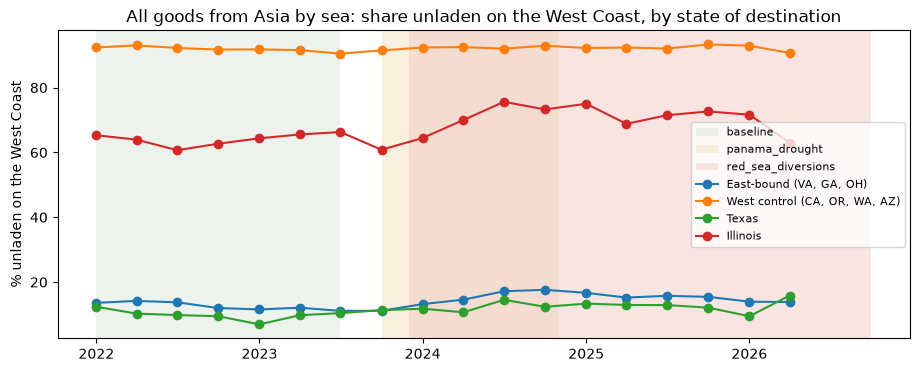

group,baseline,panama_drought,red_sea_diversions
str,f64,f64,f64
"""East-bound (VA, GA, OH)""",0.129,0.147,0.153
"""West control (CA, OR, WA, AZ)""",0.921,0.923,0.923
"""Texas""",0.098,0.121,0.126
"""Illinois""",0.638,0.688,0.706


In [9]:
groups = {
    "East-bound (VA, GA, OH)": EAST_BOUND,
    "West control (CA, OR, WA, AZ)": WEST_CONTROL,
    "Texas": ["TX"],
    "Illinois": ["IL"],
}
west_share = {
    label: case2.quarter_share(state_port, states, "west") for label, states in groups.items()
}
fig, ax = plt.subplots(figsize=(11, 4))
shade_windows(ax)
for label, series in west_share.items():
    ax.plot(list(series), [v * 100 for v in series.values()], marker="o", label=label)
ax.set_ylabel("% unladen on the West Coast")
ax.set_title("All goods from Asia by sea: share unladen on the West Coast, by state of destination")
ax.legend(fontsize=8)
plt.show()

check1 = pl.DataFrame(
    [
        {"group": label, "window": name, "west_share": s.mean, "quarters": s.months}
        for label, series in west_share.items()
        for name, s in window_summary(series, windows).items()
    ]
).pivot(on="window", index="group", values="west_share")
check1

**Inland-routing check 2, the case codes** (Census state tables, monthly): the gear's Asian vessel tonnage bound for the East-bound states and the control states, as tonnes per month in each window.

In [10]:
months_in = {
    w.name: (w.last.year - w.first.year) * 12 + w.last.month - w.first.month + 1 for w in windows
}
state_groups = {"East-bound": EAST_BOUND, "West control": WEST_CONTROL, "TX and IL": SEPARATE}
check2 = (
    cases.with_window(
        state_tonnes.filter((pl.col("region") == "asia") & (pl.col("mode") == "vessel")), windows
    )
    .drop_nulls("window")
    .with_columns(
        pl.col("state")
        .replace_strict(
            {s: g for g, states in state_groups.items() for s in states}, default="other states"
        )
        .alias("group")
    )
    .group_by("window", "group")
    .agg(pl.col("weight_t").sum())
    .with_columns(
        (pl.col("weight_t") / pl.col("window").replace_strict(months_in)).alias("t_per_month")
    )
    .pivot(on="window", index="group", values="t_per_month")
    .select("group", *[w.name for w in windows])
    .sort("group")
)
check2

group,baseline,panama_drought,red_sea_diversions
str,f64,f64,f64
"""East-bound""",784.422,2961.444,1480.996
"""TX and IL""",1397.100,3260.630,3322.832
"""West control""",1959.272,5395.996,6392.874
"""other states""",2038.209,4479.640,4787.656


## 5. Mode

The air share of the gear's tonnage from Asia, and the diversion rate from vessel to air (the proposal's r).

In [11]:
asia_supply = supply.filter(pl.col("census_cty_code").is_in(asian))
mode_shares = cases.window_shares(asia_supply, windows, ["mode"])
mode_table = mode_shares.pivot(on="window", index="mode", values="share").select(
    "mode", *[w.name for w in windows]
)
base_share = dict(zip(mode_table["mode"], mode_table["baseline"], strict=True))
air_diversion = {
    w.name: diversion_rate(
        s_from_baseline=base_share["vessel"],
        s_to_baseline=base_share["air"],
        s_to_response=mode_table.filter(pl.col("mode") == "air")[w.name].item(),
    )
    for w in shock_windows
}
print({k: round(v, 4) for k, v in air_diversion.items()})
mode_table

{'panama_drought': -0.0033, 'red_sea_diversions': 0.0067}


mode,baseline,panama_drought,red_sea_diversions
str,f64,f64,f64
"""air""",0.007,0.004,0.014
"""vessel""",0.993,0.996,0.986


## 6. Delivery emissions per tonne, by lane

A lane here is an origin × coast of arrival × mode. Its emissions per tonne are distance × factor over its legs (`shockt_engine.lane_legs`): the sea leg (observed where voyages exist) or air leg, then the inland leg from the US port to the destination states, weighted by the origin's destination states. The independence assumption of Case 1 applies: a lane's destinations are the origin's, whichever coast it arrives on.

In [12]:
lane_rows = []
for iso3 in NAMED_ORIGINS + SUEZ_EXAMPLES:
    for coast in case2.COASTS:
        for w in windows:
            result, reason = case2.lane_result(
                context, cty_code[iso3], iso3, GEAR, "vessel", w, coast
            )
            if result is None:
                continue
            parts = case2.intensity_parts(result)
            lane_rows.append(
                {
                    "iso3": iso3,
                    "coast": coast,
                    "window": w.name,
                    **parts,
                    "total": result.kg_co2e_per_t,
                }
            )
lanes = pl.DataFrame(lane_rows)
lanes.pivot(on="window", index=["iso3", "coast"], values="total").sort("iso3", "coast")

iso3,coast,baseline,panama_drought,red_sea_diversions
str,str,f64,f64,f64
"""CHN""","""east""",839.908,850.575,864.491
"""CHN""","""gulf""",617.675,634.836,667.071
"""CHN""","""west""",568.679,564.648,534.780
"""IND""","""east""",639.659,735.260,754.423
"""IND""","""gulf""",638.340,603.186,586.441
"""IND""","""west""",817.220,851.065,885.708
"""KOR""","""east""",748.219,774.492,772.084
"""KOR""","""gulf""",680.510,691.088,683.104
"""KOR""","""west""",599.948,581.880,571.983


**Freight bound for the East-bound states.** For each origin and window, the emissions per tonne of reaching Virginia, Georgia and Ohio (weighted by the origin's own vessel tonnage to them) by four routes: all-water to an East Coast port then truck; to a Gulf port then truck; to a West Coast port then rail; and to a West Coast port then truck. These are the alternatives the calculator will offer; here they are measured, not recommended.

In [13]:
routes = [("east", "truck"), ("gulf", "truck"), ("west", "rail"), ("west", "truck")]
alt_rows = []
for iso3 in NAMED_ORIGINS:
    for w in (by_name["baseline"], *shock_windows):
        row = {"iso3": iso3, "window": w.name}
        for coast, inland in routes:
            result, _ = case2.lane_result(
                context, cty_code[iso3], iso3, GEAR, "vessel", w, coast, inland, EAST_BOUND
            )
            row[f"{coast} + {inland}"] = result.kg_co2e_per_t if result else None
        alt_rows.append(row)
alternatives = pl.DataFrame(alt_rows)
alternatives

iso3,window,east + truck,gulf + truck,west + rail,west + truck
str,str,f64,f64,f64,f64
"""KOR""","""baseline""",530.880,574.046,266.764,785.849
"""KOR""","""panama_drought""",543.535,591.253,266.322,784.751
"""KOR""","""red_sea_diversions""",532.951,608.249,267.483,791.904
"""CHN""","""baseline""",563.483,647.811,297.613,811.907
"""CHN""","""panama_drought""",557.595,697.407,298.782,841.770
"""CHN""","""red_sea_diversions""",579.125,634.499,293.072,807.403
"""TWN""","""baseline""",437.126,709.626,297.486,924.340
"""TWN""","""panama_drought""",432.607,729.610,304.726,904.883
"""TWN""","""red_sea_diversions""",441.934,715.942,303.841,902.004


## 7. The supply mix and what moved it

The emissions per tonne of all the gear's Asian air and vessel supply in each window, from every origin × coast × mode lane that can be measured (`case2.mix_cells`). The change from the baseline is split between five factors with `shockt_engine.mix_decomposition`: the origin shares, each origin's coast shares, the air share within each origin and coast, and the lanes' two legs: the international leg (where route length shows) and the inland leg. Each factor's effect is its Shapley value, so the effects sum to the change.

In [14]:
mix = {}
left_out = []
for w in windows:
    cells, report = case2.mix_cells(asia_ports, context, GEAR, w)
    mix[w.name] = cells
    left_out.append(
        report.group_by("window").agg(
            pl.col("weight_t").sum().alias("t"),
            pl.col("weight_t").filter(pl.col("left_out").is_not_null()).sum().alias("t_left_out"),
        )
    )
print(
    pl.concat(left_out).with_columns((pl.col("t_left_out") / pl.col("t")).alias("share_left_out"))
)

decomposition_rows = []
for w in shock_windows:
    d = mix_decomposition(mix["baseline"], mix[w.name], ["origin", "coast", "mode"])
    decomposition_rows.append(
        {
            "window": w.name,
            "baseline_kg_per_t": d.baseline,
            "window_kg_per_t": d.window,
            "change": d.window / d.baseline - 1,
            **{f"effect: {k}": v for k, v in d.effects.items()},
        }
    )
decomposition = pl.DataFrame(decomposition_rows)
decomposition

shape: (3, 4)
┌────────────────────┬────────────┬────────────┬────────────────┐
│ window             ┆ t          ┆ t_left_out ┆ share_left_out │
│ ---                ┆ ---        ┆ ---        ┆ ---            │
│ str                ┆ f64        ┆ f64        ┆ f64            │
╞════════════════════╪════════════╪════════════╪════════════════╡
│ baseline           ┆ 111988.778 ┆ 1729.032   ┆ 0.015          │
│ panama_drought     ┆ 210017.860 ┆ 1339.827   ┆ 0.006          │
│ red_sea_diversions ┆ 735270.022 ┆ 9022.025   ┆ 0.012          │
└────────────────────┴────────────┴────────────┴────────────────┘


window,baseline_kg_per_t,window_kg_per_t,change,effect: origin,effect: coast,effect: mode,effect: inland,effect: international
str,f64,f64,f64,f64,f64,f64,f64,f64
"""panama_drought""",706.732,681.921,-0.035,111.831,-36.974,-98.513,-9.969,8.813
"""red_sea_diversions""",706.732,692.388,-0.020,69.136,-5.033,-79.743,-6.383,7.679


## 8. Findings

The DERIVED statements below are computed from the cells above, so they change with the data. The INFERENCE that follows is the team's reading and must cite them.

In [15]:
red = by_name["red_sea_diversions"]
pan = by_name["panama_drought"]
rs = decomposition.filter(pl.col("window") == red.name).row(0, named=True)
pd_ = decomposition.filter(pl.col("window") == pan.name).row(0, named=True)
east_route = route_length.filter(pl.col("coast") == "east").row(0, named=True)
gulf_route = route_length.filter(pl.col("coast") == "gulf").row(0, named=True)
via = passage_shares.filter(pl.col("window") == "baseline").row(0, named=True)
west = coast_table.filter(pl.col("coast") == "west").row(0, named=True)
eb = check1.filter(pl.col("group").str.starts_with("East-bound")).row(0, named=True)
ctrl = check2.filter(pl.col("group") == "West control").row(0, named=True)
east_bound_t = check2.filter(pl.col("group") == "East-bound").row(0, named=True)
air = mode_table.filter(pl.col("mode") == "air").row(0, named=True)
dated = {s: " to ".join(d["runs"][0]) for s, d in dating.items()}

findings = [
    f"PortWatch transits date the Panama drought window to {dated['panama_drought']} (all ship "
    f"types below the 2022-01 to 2023-06 range) and the Red Sea diversions window to "
    f"{dated['red_sea_diversions']} (container ships), open at the last full month.",
    f"Container voyages from Asia to the East Coast averaged {east_route['baseline']:,.0f} km in "
    f"the baseline and {east_route[red.name]:,.0f} km in the Red Sea window "
    f"({east_route[red.name] / east_route['baseline'] - 1:+.1%}); to the Gulf "
    f"{gulf_route['baseline']:,.0f} and {gulf_route[red.name]:,.0f} km.",
    f"In the baseline, {via['panama']:.0%} of the gear's Asian vessel tonnage to the East and Gulf "
    f"coasts was on lanes whose open route uses Panama and {via['red_sea']:.0%} on lanes that use "
    f"the Red Sea.",
    f"The West Coast's share of the gear's Asian vessel tonnage was {west['baseline']:.1%} in the "
    f"baseline, {west[pan.name]:.1%} in the Panama window and {west[red.name]:.1%} in the Red Sea "
    f"window.",
    f"For all goods from Asia by sea bound for Virginia, Georgia and Ohio, the share unladen on "
    f"the West Coast averaged {eb['baseline']:.1%} in the baseline, {eb[pan.name]:.1%} in the "
    f"Panama window and {eb[red.name]:.1%} in the Red Sea window.",
    f"The gear's Asian vessel tonnage bound for the West Coast control states averaged "
    f"{ctrl['baseline']:,.0f} t a month in the baseline and {ctrl[red.name]:,.0f} t in the Red Sea "
    f"window; bound for the East-bound states, {east_bound_t['baseline']:,.0f} and "
    f"{east_bound_t[red.name]:,.0f} t.",
    f"Air carried {air['baseline']:.2%} of the gear's tonnage from Asia in the baseline, "
    f"{air[pan.name]:.2%} in the Panama window and {air[red.name]:.2%} in the Red Sea window.",
    f"The gear's Asian supply emitted {rs['baseline_kg_per_t']:,.0f} kg CO2e per tonne delivered "
    f"in the baseline, {pd_['window_kg_per_t']:,.0f} in the Panama window "
    f"({pd_['change']:+.1%}) and {rs['window_kg_per_t']:,.0f} in the Red Sea window "
    f"({rs['change']:+.1%}). Of the Red Sea change, the international legs (route length) "
    f"account for {rs['effect: international']:+,.1f} kg, the origin mix "
    f"{rs['effect: origin']:+,.1f}, the air share within each origin and coast "
    f"{rs['effect: mode']:+,.1f}, the coast of arrival {rs['effect: coast']:+,.1f} and the "
    f"inland legs {rs['effect: inland']:+,.1f}.",
    "For the gear's freight bound for Virginia, Georgia and Ohio in the baseline, a West Coast "
    "port then rail emitted "
    + ", ".join(
        f"{r['iso3']} {r['west + rail']:,.0f}"
        for r in alternatives.filter(pl.col("window") == "baseline").to_dicts()
    )
    + " kg CO2e per tonne, against "
    + ", ".join(
        f"{r['iso3']} {r['east + truck']:,.0f}"
        for r in alternatives.filter(pl.col("window") == "baseline").to_dicts()
    )
    + " all-water to an East Coast port then truck.",
]
print("\n".join(f"- {f}" for f in findings))

- PortWatch transits date the Panama drought window to 2023-10 to 2024-10 (all ship types below the 2022-01 to 2023-06 range) and the Red Sea diversions window to 2023-12 to 2026-09 (container ships), open at the last full month.
- Container voyages from Asia to the East Coast averaged 18,279 km in the baseline and 20,783 km in the Red Sea window (+13.7%); to the Gulf 18,915 and 19,334 km.
- In the baseline, 83% of the gear's Asian vessel tonnage to the East and Gulf coasts was on lanes whose open route uses Panama and 17% on lanes that use the Red Sea.
- The West Coast's share of the gear's Asian vessel tonnage was 40.1% in the baseline, 43.1% in the Panama window and 50.3% in the Red Sea window.
- For all goods from Asia by sea bound for Virginia, Georgia and Ohio, the share unladen on the West Coast averaged 12.9% in the baseline, 14.7% in the Panama window and 15.3% in the Red Sea window.
- The gear's Asian vessel tonnage bound for the West Coast control states averaged 1,959 t a m

**What the data suggests (INFERENCE, for the team to review).** The Red Sea diversions lengthened the voyages that used Suez, and the observed distances show it for those lanes (India and Vietnam to the East Coast). But most of the gear comes from Korea, China and Taiwan, whose East and Gulf Coast lanes sail via Panama, and the Canal Authority gave container ships priority during the drought, so their routes barely lengthened. For the gear as a whole, route length therefore moved emissions per tonne by about one percent. The origin mix and the air share within each origin and coast moved it more, in opposite directions, and neither is clearly a response to either shock. The West Coast's rising share of the gear's arrivals goes with fast growth in freight bound for western states; the all-goods check shows a smaller shift of East-bound freight to West Coast ports while the control states held, which supports the proposal's inland-routing inference as a contributing factor, not the main driver. For freight bound for the East-bound states, landing on the West Coast and moving east by rail is the lowest-emission route measured, well below all-water to the East Coast with a truck leg.

**What it can't say.** Monthly data can't separate the two overlapping shocks from each other or from the AI-driven growth in western demand; the container voyages stand for most of the gear but not for half of the largest transformers (850423), which also move on other ships; state of destination is the destination known at entry, not where the gear is installed; and a lane's destinations are the origin's, whichever coast it lands on.

## 9. Write the derived evidence and propose causal labels

`evidence_derived.yaml` is regenerated on every run; don't edit it by hand. `causal_labels.proposed.yaml` is a starting point: the analyst copies what holds into `causal_labels.yaml`.

In [16]:
provenance = {
    "notebook": NOTEBOOK,
    "git_commit": cases.git_commit(),
    "windows_file": "inputs/cases/panama_red_sea_2023/shock_windows.yaml",
    "run_at": date.today().isoformat(),
    "data": loads.to_dicts(),
}
derived = [
    {
        "id": "ev_derived_case2_shock_windows",
        "basis": "DERIVED",
        "claim": findings[0],
        "metric": "shockt_engine.months_outside_range",
        "parameters": {"windows_file": "inputs/cases/panama_red_sea_2023/shock_windows.yaml"},
        "values": dating,
    },
    {
        "id": "ev_derived_case2_voyage_distance",
        "basis": "DERIVED",
        "claim": findings[1],
        "metric": "shockt_engine.window_summary",
        "parameters": {"origin_region": "asia", "source": "core.agg_voyage_lanes_monthly"},
        "values": {
            r["coast"]: {w.name: round(r[w.name]) for w in windows} for r in route_length.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_passage_tonnage",
        "basis": "DERIVED",
        "claim": findings[2],
        "metric": "shockt_engine.passage_used",
        "parameters": {
            "hs6": GEAR,
            "coasts": ["east", "gulf"],
            "tolerance_km": PASSAGE_TOLERANCE_KM,
        },
        "values": {
            r["window"]: {k: round(r[k], 4) for k in ("panama", "red_sea", "neither")}
            for r in passage_shares.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_coast_shares",
        "basis": "DERIVED",
        "claim": findings[3],
        "metric": "shockt_engine.shares",
        "parameters": {"hs6": GEAR, "origin_region": "asia", "mode": "vessel"},
        "values": {
            r["coast"]: {w.name: round(r[w.name], 4) for w in windows}
            for r in coast_table.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_east_bound_west_share",
        "basis": "DERIVED",
        "claim": findings[4],
        "metric": "shockt_engine.window_summary",
        "parameters": {
            "source": "core.fct_imports_state_port_quarterly",
            "origin_region": "asia",
            "groups": groups,
        },
        "values": {
            r["group"]: {w.name: round(r[w.name], 4) for w in windows if r.get(w.name) is not None}
            for r in check1.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_state_tonnage",
        "basis": "DERIVED",
        "claim": findings[5],
        "metric": "tonnes per month by window",
        "parameters": {
            "hs6": GEAR,
            "origin_region": "asia",
            "mode": "vessel",
            "groups": state_groups,
        },
        "values": {
            r["group"]: {w.name: round(r[w.name], 1) for w in windows if r.get(w.name) is not None}
            for r in check2.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_air_share",
        "basis": "DERIVED",
        "claim": findings[6],
        "metric": "shockt_engine.diversion_rate",
        "parameters": {"hs6": GEAR, "origin_region": "asia"},
        "values": {
            "air_share": {w.name: round(air[w.name], 5) for w in windows},
            "vessel_to_air_rate": {k: round(v, 5) for k, v in air_diversion.items()},
        },
    },
    {
        "id": "ev_derived_case2_east_bound_routes",
        "basis": "DERIVED",
        "claim": findings[8],
        "metric": "shockt_engine.lane_legs",
        "parameters": {
            "hs6": GEAR,
            "states": EAST_BOUND,
            "routes": [f"{c} + {i}" for c, i in routes],
        },
        "values": {
            f"{r['iso3']}_{r['window']}": {
                k: round(v, 1) for k, v in r.items() if isinstance(v, float)
            }
            for r in alternatives.to_dicts()
        },
    },
    {
        "id": "ev_derived_case2_mix_decomposition",
        "basis": "DERIVED",
        "claim": findings[7],
        "metric": "shockt_engine.mix_decomposition",
        "parameters": {
            "hs6": GEAR,
            "origin_region": "asia",
            "dimensions": ["origin", "coast", "mode"],
            "leg_factors": "engine/config/leg_factors.yaml",
        },
        "values": {
            r["window"]: {
                k: round(v, 1) if isinstance(v, float) else v for k, v in r.items() if k != "window"
            }
            for r in decomposition.to_dicts()
        },
    },
]
cases.write_derived(CASE_DIR / "evidence_derived.yaml", CASE, derived, provenance)

proposed = {
    "case": CASE,
    "status": "proposed",
    "labels": [
        {
            "lane": "Asia → US East Coast via Suez",
            "observed_response": "Observed voyage distances rose to near the Cape route's.",
            "proposed_status": "DIRECT_CAUSAL",
            "competing_explanations": [
                "The Panama restrictions in the same months, for lanes that could use either"
            ],
            "evidence": [
                "ev_redsea_maersk_cape_diversion_2024_01",
                "ev_derived_case2_voyage_distance",
                "ev_derived_case2_passage_tonnage",
            ],
            "note": "Holds for the Suez lanes; most of the gear's tonnage is on Panama lanes.",
        },
        {
            "lane": "Asia → US East and Gulf coasts via Panama",
            "observed_response": "Observed voyage distances rose only slightly.",
            "proposed_status": "TEMPORAL_ALIGNMENT",
            "competing_explanations": [
                "Container ships kept priority for Panama slots",
                "Port mix within the lane",
            ],
            "evidence": ["ev_panama_acp_a35_2023_capacity_cut", "ev_derived_case2_voyage_distance"],
        },
        {
            "lane": "Asia → US, gear by sea",
            "observed_response": "The West Coast's share of arrivals rose.",
            "proposed_status": "CONTRIBUTING_FACTOR",
            "competing_explanations": [
                "Growth in freight bound for western states (data center build-out)",
                "East Coast port labor dispute risk in 2024",
            ],
            "evidence": [
                "ev_derived_case2_coast_shares",
                "ev_derived_case2_east_bound_west_share",
                "ev_derived_case2_state_tonnage",
            ],
            "note": "Downgrade to TEMPORAL_ALIGNMENT if East-bound freight didn't shift west.",
        },
    ],
}
(CASE_DIR / "causal_labels.proposed.yaml").write_text(
    "# Proposed by the Case 2 notebook; copy what holds into causal_labels.yaml.\n"
    + yaml.safe_dump(proposed, sort_keys=False, allow_unicode=True, width=100)
)
print(
    "Wrote",
    (CASE_DIR / "evidence_derived.yaml").relative_to(REPO_ROOT),
    "and",
    (CASE_DIR / "causal_labels.proposed.yaml").relative_to(REPO_ROOT),
)

Wrote inputs/cases/panama_red_sea_2023/evidence_derived.yaml and inputs/cases/panama_red_sea_2023/causal_labels.proposed.yaml
